<a href="https://colab.research.google.com/github/Muralikrishna019/Structured-Document-Extraction-with-a-QLoRA-Fine-Tuned-LLM/blob/main/Structured_Document_Extraction_with_a_QLoRA_Fine_Tuned_LLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Receipt text → JSON: QLoRA fine-tuning of Qwen2.5-3B on CORD-v2
Runs on a free Colab **T4 GPU**. Sections: setup → data → baseline → fine-tune → evaluation → leakage check → error analysis → robustness → export.

**Key results (test split, n=100):** exact match 8% → 71% (95% CI 62–80); 69.3% after removing near-duplicate test receipts; field F1 0.753 → 0.983; item F1 0.394 → 0.877.
All numbers below come from the 4-bit model + LoRA adapter, **not** the quantized GGUF (GGUF evaluation is the last section; run it to complete the record).

## 1. Setup

In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

In [ ]:
!pip install -q unsloth
!pip install -q datasets pydantic matplotlib pandas

In [ ]:
import os, json, re, random, gc, time
import numpy as np, torch, pandas as pd
from collections import Counter, defaultdict
from typing import List, Optional

print("CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount("/content/drive")
PROJECT_DIR = "/content/drive/MyDrive/receipt_extraction_llm"
os.makedirs(PROJECT_DIR, exist_ok=True)

CFG = dict(
    base_model="unsloth/Qwen2.5-3B-Instruct-bnb-4bit",  # if you hit OOM: unsloth/Qwen2.5-1.5B-Instruct-bnb-4bit
    max_seq_length=2048,
    lora_r=16, lora_alpha=32,
    epochs=2, lr=2e-4, batch_size=2, grad_accum=4,
    seed=3407,
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])
json.dump(CFG, open(f"{PROJECT_DIR}/config.json", "w"), indent=2)

CUDA: True | Tesla T4
Mounted at /content/drive


## 2. Data: CORD-v2 → (receipt text, target JSON)

In [ ]:
from datasets import load_dataset
raw = load_dataset("naver-clova-ix/cord-v2")
print(raw)

gt = json.loads(raw["train"][0]["ground_truth"])
print(list(gt.keys()))
print(json.dumps(gt["gt_parse"], indent=1)[:1200])

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

...

data/test-00000-of-00001-9c204eb3f4e1179(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 800
    })
    validation: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
    test: Dataset({
        features: ['image', 'ground_truth'],
        num_rows: 100
    })
})
['gt_parse', 'meta', 'valid_line', 'roi', 'repeating_symbol', 'dontcare']
{
 "menu": [
  {
   "nm": "Nasi Campur Bali",
   "cnt": "1 x",
   "price": "75,000"
  },
  {
   "nm": "Bbk Bengil Nasi",
   "cnt": "1 x",
   "price": "125,000"
  },
  {
   "nm": "MilkShake Starwb",
   "cnt": "1 x",
   "price": "37,000"
  },
  {
   "nm": "Ice Lemon Tea",
   "cnt": "1 x",
   "price": "24,000"
  },
  {
   "nm": "Nasi Ayam Dewata",
   "cnt": "1 x",
   "price": "70,000"
  },
  {
   "nm": "Free Ice Tea",
   "cnt": "3 x",
   "price": "0"
  },
  {
   "nm": "Organic Green Sa",
   "cnt": "1 x",
   "price": "65,000"
  },
  {
   "nm": "Ice Tea",
   "cnt": "1 x",
   "price": "18,000"
  },
  {
   "nm": "Ice Or

In [ ]:
from pydantic import BaseModel

class Item(BaseModel):
    name: Optional[str] = None
    quantity: Optional[str] = None
    price: Optional[str] = None

class Receipt(BaseModel):
    items: List[Item]
    subtotal: Optional[str] = None
    tax: Optional[str] = None
    total: Optional[str] = None
    cash: Optional[str] = None
    change: Optional[str] = None

def as_dict(x):
    if isinstance(x, list): x = x[0] if x else {}
    return x if isinstance(x, dict) else {}

def first(x):
    if isinstance(x, list): x = x[0] if x else None
    if isinstance(x, dict) or x is None: return None
    return str(x).strip() or None

def build_receipt_text(gt):
    rows = defaultdict(list)
    for line in gt["valid_line"]:
        for w in line["words"]:
            rows[w["row_id"]].append((w["quad"]["x1"], w["text"]))
    return "\n".join(" ".join(t for _, t in sorted(rows[r])) for r in sorted(rows))

def build_target(gt):
    p = gt["gt_parse"]
    menu = p.get("menu", [])
    if isinstance(menu, dict): menu = [menu]
    items = [{"name": first(m.get("nm")), "quantity": first(m.get("cnt")), "price": first(m.get("price"))}
             for m in menu if isinstance(m, dict)]
    st, tt = as_dict(p.get("sub_total")), as_dict(p.get("total"))
    return {
        "items": items,
        "subtotal": first(st.get("subtotal_price")),
        "tax": first(st.get("tax_price")),
        "total": first(tt.get("total_price")),
        "cash": first(tt.get("cashprice")),
        "change": first(tt.get("changeprice")),
    }

SCHEMA_STR = json.dumps(Receipt.model_json_schema())
SYSTEM_PROMPT = (
    "You are an information extraction engine. Convert the receipt text into JSON that "
    "follows this schema exactly. Use null for missing fields. Keep values exactly as written "
    "on the receipt. Output JSON only.\nSchema: " + SCHEMA_STR
)

def make_example(ex):
    gt = json.loads(ex["ground_truth"])
    text, target = build_receipt_text(gt), build_target(gt)
    Receipt.model_validate(target)  # sanity: our own labels follow the schema
    return {"receipt_text": text, "target": json.dumps(target, ensure_ascii=False, separators=(",", ":"))}

data = raw.map(make_example, remove_columns=raw["train"].column_names)
print(data)
print(data["train"][0]["receipt_text"][:500])
print(data["train"][0]["target"][:500])

/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot locate reference to <class '__main__.Item'>.
  StockPickler.save(self, obj, save_persistent_id)
/usr/local/lib/python3.13/dist-packages/dill/_dill.py:423: PicklingWarning: Cannot pickle <class '__main__.Item'>: __main__.Item has recursive self-references that trigger a RecursionError.
  StockPickler.save(self, obj, save_persistent_id)
Parameter 'function'=<function make_example at 0x7bfadbb3f600> of the transform datasets.arrow_dataset.Dataset._map_single couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only shown once. Subsequent hashing failures won't be shown.


Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['receipt_text', 'target'],
        num_rows: 800
    })
    validation: Dataset({
        features: ['receipt_text', 'target'],
        num_rows: 100
    })
    test: Dataset({
        features: ['receipt_text', 'target'],
        num_rows: 100
    })
})
1 x Nasi Campur Bali 75,000
1 x Bbk Bengil Nasi 125,000
1 x MilkShake Starwb 37,000
1 x Ice Lemon Tea 24,000
1 x Nasi Ayam Dewata 70,000
3 x Free Ice Tea 0
1 x Organic Green Sa 65,000
1 x Ice Tea 18,000
1 x Ice Orange 29,000
1 x Ayam Suir Bali 85,000
2 x Tahu Goreng 36,000
2 x Tempe Goreng 36,000
1 x Tahu Telor Asin 40,000.
1 x Nasi Goreng Samb 70,000
3 x Bbk Panggang Sam 366,000
1 x Ayam Sambal Hija 92,000
2 x Hot Tea 44,000
1 x Ice Kopi 32,000
1 x Tahu Telor Asin 40,000
1 x Free Ice Tea 0
1 x 
{"items":[{"name":"Nasi Campur Bali","quantity":"1 x","price":"75,000"},{"name":"Bbk Bengil Nasi","quantity":"1 x","price":"125,000"},{"name":"MilkShake Starwb","quantity":"1 x","price":"37,

## 3. Prompts and token lengths

In [ ]:
from unsloth import FastLanguageModel
from transformers import AutoTokenizer

tok_check = AutoTokenizer.from_pretrained(CFG["base_model"])

def to_messages(receipt_text, target=None):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Receipt text:\n{receipt_text}"}]
    if target is not None:
        msgs.append({"role": "assistant", "content": target})
    return msgs

def add_text(ex):
    return {"text": tok_check.apply_chat_template(to_messages(ex["receipt_text"], ex["target"]), tokenize=False)}

data = data.map(add_text)
data = data.map(lambda ex: {"n_tok": len(tok_check(ex["text"]).input_ids)})
for s in data: print(s, "max tokens:", max(data[s]["n_tok"]), "| mean:", int(np.mean(data[s]["n_tok"])))

train_ds = data["train"].filter(lambda ex: ex["n_tok"] <= CFG["max_seq_length"])
val_ds, test_ds = data["validation"], data["test"]
print(len(train_ds), len(val_ds), len(test_ds))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!


train max tokens: 1261 | mean: 572
validation max tokens: 911 | mean: 548
test max tokens: 902 | mean: 564


800 100 100


## 4. Evaluation harness
JSON validity, schema validity, field F1, item F1, exact match (normalized: case/space/punctuation ignored).

In [ ]:
def norm(v):
    if v is None: return None
    s = re.sub(r"[^0-9a-z]", "", str(v).lower())
    return s or None

def parse_json(text):
    t = text.strip()
    t = re.sub(r"^```(?:json)?|```$", "", t, flags=re.M).strip()
    try:
        return json.loads(t)
    except Exception:
        m = re.search(r"\{.*\}", t, flags=re.S)
        if m:
            try: return json.loads(m.group(0))
            except Exception: return None
    return None

SCALARS = ["subtotal", "tax", "total", "cash", "change"]

def item_tuples(d):
    return Counter((norm(i.get("name")), norm(i.get("quantity")), norm(i.get("price")))
                   for i in d.get("items", []) if isinstance(i, dict))

def evaluate(preds, golds):
    n = len(golds); valid = schema_ok = exact = 0
    tp = fp = fn = 0
    itp = ifp = ifn = 0
    per_field = {f: [0, 0, 0] for f in SCALARS}
    for raw_pred, gold in zip(preds, golds):
        obj = parse_json(raw_pred)
        pred = None
        if isinstance(obj, dict):
            valid += 1
            try: Receipt.model_validate(obj); schema_ok += 1; pred = obj
            except Exception: pred = obj
        pred = pred if isinstance(pred, dict) else {}
        for f in SCALARS:
            p, g = norm(pred.get(f)), norm(gold.get(f))
            if g is not None and p == g: tp += 1; per_field[f][0] += 1
            else:
                if p is not None: fp += 1; per_field[f][1] += 1
                if g is not None: fn += 1; per_field[f][2] += 1
        pi, gi = item_tuples(pred) if isinstance(pred.get("items", []), list) else Counter(), item_tuples(gold)
        inter = sum((pi & gi).values())
        itp += inter; ifp += sum(pi.values()) - inter; ifn += sum(gi.values()) - inter
        if all(norm(pred.get(f)) == norm(gold.get(f)) for f in SCALARS) and pi == gi: exact += 1
    f1 = lambda a, b, c: 2*a / (2*a + b + c) if (2*a + b + c) else 0.0
    return {
        "json_valid_%": 100*valid/n, "schema_valid_%": 100*schema_ok/n,
        "field_f1": f1(tp, fp, fn), "item_f1": f1(itp, ifp, ifn),
        "exact_match_%": 100*exact/n,
        "per_field_f1": {f: f1(*v) for f, v in per_field.items()},
    }

def generate(model, tokenizer, receipt_texts, bs=8, max_new_tokens=768):
    tokenizer.padding_side = "left"
    prompts = [tokenizer.apply_chat_template(to_messages(t), tokenize=False, add_generation_prompt=True)
               for t in receipt_texts]
    outs = []
    for i in range(0, len(prompts), bs):
        enc = tokenizer(prompts[i:i+bs], return_tensors="pt", padding=True).to("cuda")
        with torch.no_grad():
            g = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True)
        outs += tokenizer.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

gold_test = [json.loads(t) for t in test_ds["target"]]
RESULTS = {}

## 5. Baseline: base model, zero-shot

In [ ]:
model, tokenizer = FastLanguageModel.from_pretrained(
    CFG["base_model"], max_seq_length=CFG["max_seq_length"], dtype=None, load_in_4bit=True)
FastLanguageModel.for_inference(model)

t0 = time.time()
base_preds = generate(model, tokenizer, test_ds["receipt_text"])
RESULTS["Base (zero-shot)"] = evaluate(base_preds, gold_test)
print(f"{time.time()-t0:.0f}s"); print(json.dumps(RESULTS["Base (zero-shot)"], indent=1))
json.dump(RESULTS, open(f"{PROJECT_DIR}/results.json", "w"), indent=2)

del model, tokenizer; gc.collect(); torch.cuda.empty_cache()

483s
{
 "json_valid_%": 100.0,
 "schema_valid_%": 95.0,
 "field_f1": 0.7529761904761905,
 "item_f1": 0.3938223938223938,
 "exact_match_%": 8.0,
 "per_field_f1": {
  "subtotal": 0.7547169811320755,
  "tax": 0.575,
  "total": 0.7659574468085106,
  "cash": 0.7887323943661971,
  "change": 0.8155339805825242
 }
}


## 6. Fine-tuning (QLoRA, loss on the JSON answer only)

In [ ]:
model, tokenizer = FastLanguageModel.from_pretrained(
    CFG["base_model"], max_seq_length=CFG["max_seq_length"], dtype=None, load_in_4bit=True)

model = FastLanguageModel.get_peft_model(
    model, r=CFG["lora_r"], lora_alpha=CFG["lora_alpha"], lora_dropout=0, bias="none",
    target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"],
    use_gradient_checkpointing="unsloth", random_state=CFG["seed"])
model.print_trainable_parameters()

In [ ]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only

trainer = SFTTrainer(
    model=model, tokenizer=tokenizer,
    train_dataset=train_ds, eval_dataset=val_ds,
    args=SFTConfig(
        dataset_text_field="text", max_seq_length=CFG["max_seq_length"], packing=False,
        per_device_train_batch_size=CFG["batch_size"], per_device_eval_batch_size=2,
        gradient_accumulation_steps=CFG["grad_accum"],
        num_train_epochs=CFG["epochs"], learning_rate=CFG["lr"],
        warmup_steps=10, lr_scheduler_type="cosine", weight_decay=0.01,
        optim="adamw_8bit", fp16=not is_bfloat16_supported(), bf16=is_bfloat16_supported(),
        logging_steps=10, eval_strategy="steps", eval_steps=50,
        save_strategy="no", seed=CFG["seed"], output_dir="outputs",
        report_to="none",  # set to "wandb" if you want experiment tracking
    ),
)
trainer = train_on_responses_only(
    trainer, instruction_part="<|im_start|>user\n", response_part="<|im_start|>assistant\n")

# Sanity check: the masked (-100) part should be the prompt; only the JSON should be learned
ex = trainer.train_dataset[0]
print(tokenizer.decode([t for t in ex["labels"] if t != -100])[:300])

{"items":[{"name":"Nasi Campur Bali","quantity":"1 x","price":"75,000"},{"name":"Bbk Bengil Nasi","quantity":"1 x","price":"125,000"},{"name":"MilkShake Starwb","quantity":"1 x","price":"37,000"},{"name":"Ice Lemon Tea","quantity":"1 x","price":"24,000"},{"name":"Nasi Ayam Dewata","quantity":"1 x","


In [ ]:
stats = trainer.train()
print(stats.metrics)

Step,Training Loss,Validation Loss
50,0.035685,0.020437
100,0.023327,0.019028
150,0.008358,0.016453
200,0.011125,0.015666


{'train_runtime': 1399.1102, 'train_samples_per_second': 1.144, 'train_steps_per_second': 0.143, 'total_flos': 1.5417061085331456e+16, 'train_loss': 0.02724530689418316, 'epoch': 2.0}


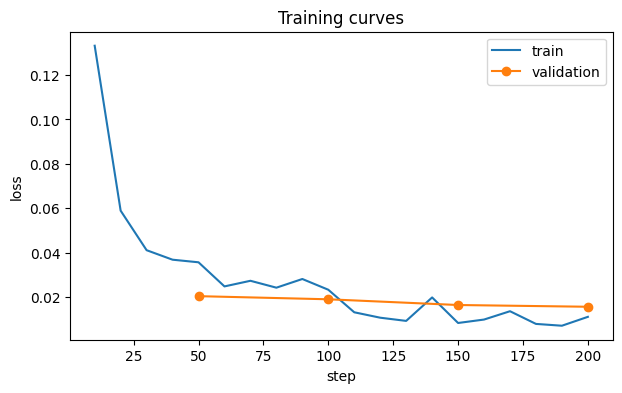

In [ ]:
import matplotlib.pyplot as plt
log = pd.DataFrame(trainer.state.log_history)
plt.figure(figsize=(7,4))
plt.plot(log.dropna(subset=["loss"])["step"], log.dropna(subset=["loss"])["loss"], label="train")
ev = log.dropna(subset=["eval_loss"])
plt.plot(ev["step"], ev["eval_loss"], "o-", label="validation")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("Training curves")
plt.savefig(f"{PROJECT_DIR}/loss_curve.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
model.save_pretrained(f"{PROJECT_DIR}/lora_adapter")
tokenizer.save_pretrained(f"{PROJECT_DIR}/lora_adapter")

## 7. Test-set evaluation (fine-tuned vs base)

In [ ]:
FastLanguageModel.for_inference(model)
ft_preds = generate(model, tokenizer, test_ds["receipt_text"])
RESULTS["Fine-tuned (QLoRA)"] = evaluate(ft_preds, gold_test)
json.dump(RESULTS, open(f"{PROJECT_DIR}/results.json", "w"), indent=2)

df = pd.DataFrame({k: {m: v for m, v in r.items() if m != "per_field_f1"} for k, r in RESULTS.items()}).T.round(3)
print(df.to_string())

                    json_valid_%  schema_valid_%  field_f1  item_f1  exact_match_%
Base (zero-shot)           100.0            95.0     0.753    0.394            8.0
Fine-tuned (QLoRA)         100.0           100.0     0.983    0.877           71.0


In [ ]:
print(pd.DataFrame({k: r["per_field_f1"] for k, r in RESULTS.items()}).round(3))

def exact_flags(preds, golds):
    out = []
    for p, g in zip(preds, golds):
        o = parse_json(p) or {}
        out.append(all(norm(o.get(f)) == norm(g.get(f)) for f in SCALARS) and item_tuples(o) == item_tuples(g))
    return np.array(out)

rng = np.random.default_rng(0)
for name, preds in [("Base", base_preds), ("Fine-tuned", ft_preds)]:
    flags = exact_flags(preds, gold_test)
    boots = [flags[rng.integers(0, len(flags), len(flags))].mean() * 100 for _ in range(2000)]
    print(f"{name}: exact match {flags.mean()*100:.0f}%  (95% CI {np.percentile(boots,2.5):.0f}-{np.percentile(boots,97.5):.0f})")

          Base (zero-shot)  Fine-tuned (QLoRA)
subtotal             0.755               0.985
tax                  0.575               0.988
total                0.766               0.984
cash                 0.789               0.969
change               0.816               0.991
Base: exact match 8%  (95% CI 3-14)
Fine-tuned: exact match 71%  (95% CI 62-80)


## 8. Error analysis (test set)

In [ ]:
bad = []
for i, (p, g) in enumerate(zip(ft_preds, gold_test)):
    o = parse_json(p) or {}
    if not (all(norm(o.get(f)) == norm(g.get(f)) for f in SCALARS) and item_tuples(o) == item_tuples(g)):
        bad.append(i)
print(f"{len(bad)}/{len(gold_test)} not exact")
for i in bad[:4]:
    print("="*80, "\nRECEIPT:\n", test_ds[i]["receipt_text"][:400])
    print("\nGOLD:", json.dumps(gold_test[i], ensure_ascii=False)[:500])
    print("PRED:", ft_preds[i][:500])

In [ ]:
cats = Counter()
for i in bad:
    o = parse_json(ft_preds[i]) or {}
    g = gold_test[i]
    if len(o.get("items", [])) != len(g["items"]): cats["wrong number of items"] += 1
    elif item_tuples(o) != item_tuples(g): cats["item field mismatch"] += 1
    if any(norm(o.get(f)) != norm(g.get(f)) for f in SCALARS): cats["scalar field mismatch"] += 1
print(cats)

In [ ]:
def raw_items(d):
    return [(i.get("name"), i.get("quantity"), i.get("price")) for i in d.get("items", []) if isinstance(i, dict)]

def key(t): return tuple(map(norm, t))

for i in bad:
    o = parse_json(ft_preds[i]) or {}
    g = gold_test[i]
    gk = {key(t) for t in raw_items(g)}
    pk = {key(t) for t in raw_items(o)}
    pred_only = [t for t in raw_items(o) if key(t) not in gk]
    gold_only = [t for t in raw_items(g) if key(t) not in pk]
    scal = {f: (g.get(f), o.get(f)) for f in SCALARS if norm(o.get(f)) != norm(g.get(f))}
    print(f"#{i} pred_only={pred_only} | gold_only={gold_only} | scalars(gold,pred)={scal}")

In [ ]:
for i in [27, 64, 79, 18, 37, 71, 30, 76, 12, 17]:
    print("="*70, f"\n#{i} RECEIPT:\n{test_ds[i]['receipt_text']}")
    print("\nGOLD:", json.dumps(gold_test[i], ensure_ascii=False))
    print("PRED:", ft_preds[i])

## 9. Validation-set analysis

In [ ]:
SUMMARY_RE = re.compile(
    r"^\W*(sub\s*total|subtotal|total|tax|pb1|ppn|service|cash|change|tunai|kembalian|dine\s*in\s*total)\b", re.I)

def postprocess(pred_text):
    obj = parse_json(pred_text)
    if not isinstance(obj, dict) or not isinstance(obj.get("items"), list):
        return pred_text
    scalar_vals = {norm(obj.get(f)) for f in SCALARS} - {None}
    kept = [it for it in obj["items"]
            if not (isinstance(it, dict) and SUMMARY_RE.match(str(it.get("name") or ""))
                    and norm(it.get("price")) in scalar_vals)]
    obj["items"] = kept
    return json.dumps(obj, ensure_ascii=False)

gold_val = [json.loads(t) for t in val_ds["target"]]
val_preds = generate(model, tokenizer, val_ds["receipt_text"])
val_raw = evaluate(val_preds, gold_val)
val_pp = evaluate([postprocess(p) for p in val_preds], gold_val)
print(pd.DataFrame({"raw": val_raw, "+postprocess": val_pp}).drop("per_field_f1").round(3))

# Same diff dump as before, now on VALIDATION failures
for i, (p, g) in enumerate(zip(val_preds, gold_val)):
    o = parse_json(p) or {}
    if not (all(norm(o.get(f)) == norm(g.get(f)) for f in SCALARS) and item_tuples(o) == item_tuples(g)):
        scal = {f: (g.get(f), o.get(f)) for f in SCALARS if norm(o.get(f)) != norm(g.get(f))}
        print(f"val#{i} scalars(gold,pred)={scal}")

In [ ]:
import transformers
transformers.logging.set_verbosity_error()  # silences the max_length warning spam

def raw_items(d):
    return [(i.get("name"), i.get("quantity"), i.get("price")) for i in d.get("items", []) if isinstance(i, dict)]
def key(t): return tuple(map(norm, t))

for i, (p, g) in enumerate(zip(val_preds, gold_val)):
    o = parse_json(p) or {}
    if all(norm(o.get(f)) == norm(g.get(f)) for f in SCALARS) and item_tuples(o) != item_tuples(g):
        gk = {key(t) for t in raw_items(g)}; pk = {key(t) for t in raw_items(o)}
        print(f"val#{i} pred_only={[t for t in raw_items(o) if key(t) not in gk]} | gold_only={[t for t in raw_items(g) if key(t) not in pk]}")

## 10. Leakage check (near-duplicate receipts between train and test)

In [ ]:
def toks(s): return set(re.findall(r"[a-z0-9]+", s.lower()))
train_toks = [toks(t) for t in train_ds["receipt_text"]]

def max_overlap(text):
    t = toks(text)
    return max(len(t & tt) / max(len(t | tt), 1) for tt in train_toks)

ov = np.array([max_overlap(t) for t in test_ds["receipt_text"]])
print("max Jaccard vs train: median %.2f | 90th pct %.2f | max %.2f" % (np.median(ov), np.percentile(ov, 90), ov.max()))
print("test receipts with overlap > 0.8:", (ov > 0.8).sum(), "/", len(ov))

flags = exact_flags(ft_preds, gold_test)
hi = ov > 0.5
print(f"exact match high-overlap (>0.5): {flags[hi].mean()*100:.0f}% (n={hi.sum()}) | low-overlap: {flags[~hi].mean()*100:.0f}% (n={(~hi).sum()})")

max Jaccard vs train: median 0.44 | 90th pct 1.00 | max 1.00
test receipts with overlap > 0.8: 25 / 100
exact match high-overlap (>0.5): 82% (n=40) | low-overlap: 63% (n=60)


In [ ]:
clean = ov <= 0.8   # test receipts with no near-duplicate in train
rng = np.random.default_rng(0)

def ci(f):
    b = [f[rng.integers(0, len(f), len(f))].mean()*100 for _ in range(2000)]
    return dict(mean=round(f.mean()*100, 1), lo=round(np.percentile(b, 2.5), 1),
                hi=round(np.percentile(b, 97.5), 1), n=int(len(f)))

ft_flags = exact_flags(ft_preds, gold_test)
base_flags = exact_flags(base_preds, gold_test)

summary = {
    "fine_tuned_full_test": ci(ft_flags),
    "fine_tuned_deduplicated": ci(ft_flags[clean]),
    "base_full_test": ci(base_flags),
    "base_deduplicated": ci(base_flags[clean]),
}
for k, v in summary.items(): print(f"{k:28s} {v}")

RESULTS["exact_match_summary"] = summary
json.dump(RESULTS, open(f"{PROJECT_DIR}/results.json", "w"), indent=2)

fine_tuned_full_test         {'mean': np.float64(71.0), 'lo': np.float64(62.0), 'hi': np.float64(80.0), 'n': 100}
fine_tuned_deduplicated      {'mean': np.float64(69.3), 'lo': np.float64(58.7), 'hi': np.float64(78.7), 'n': 75}
base_full_test               {'mean': np.float64(8.0), 'lo': np.float64(3.0), 'hi': np.float64(14.0), 'n': 100}
base_deduplicated            {'mean': np.float64(6.7), 'lo': np.float64(1.3), 'hi': np.float64(13.3), 'n': 75}


## 11. Results chart

Plotting: ['Base (zero-shot)', 'Fine-tuned (QLoRA)']


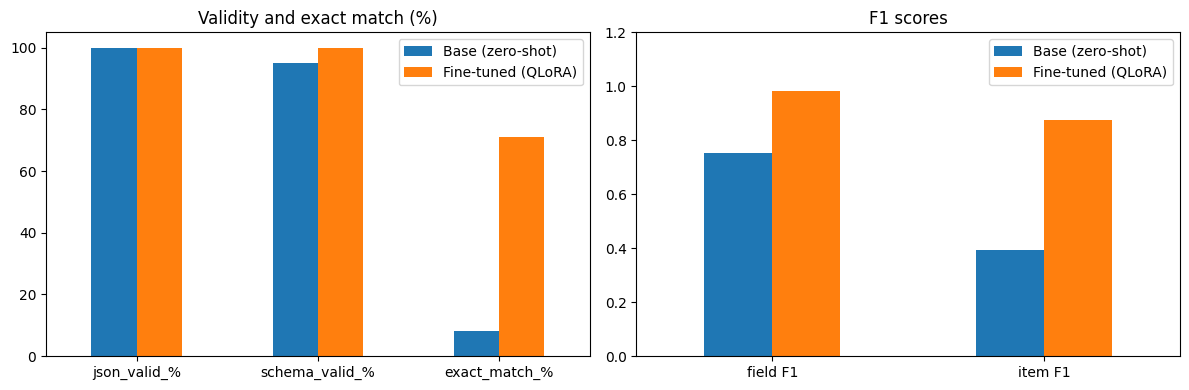

In [ ]:
model_results = {k: v for k, v in RESULTS.items() if isinstance(v, dict) and "json_valid_%" in v}
print("Plotting:", list(model_results))

metrics = ["json_valid_%", "schema_valid_%", "exact_match_%"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

pd.DataFrame({k: [r[m] for m in metrics] for k, r in model_results.items()},
             index=metrics).plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Validity and exact match (%)")

pd.DataFrame({k: [r["field_f1"], r["item_f1"]] for k, r in model_results.items()},
             index=["field F1", "item F1"]).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("F1 scores"); ax[1].set_ylim(0, 1.2)

plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/results.png", dpi=150)
plt.show()

## 12. Demo receipt and robustness

In [ ]:
sample = """STARBUCKS COFFEE
1 Caffe Latte 4.50
2 Blueberry Muffin 7.00
Subtotal 11.50
Tax 0.92
Total 12.42
Cash 20.00
Change 7.58"""
out = generate(model, tokenizer, [sample])[0]
print(json.dumps(parse_json(out), indent=2))

{
  "items": [
    {
      "name": "Caffe Latte",
      "quantity": "1",
      "price": "4.50"
    },
    {
      "name": "Blueberry Muffin",
      "quantity": "2",
      "price": "7.00"
    }
  ],
  "subtotal": "11.50",
  "tax": "0.92",
  "total": "12.42",
  "cash": "20.00",
  "change": "7.58"
}


In [ ]:
noisy = """STARBUCKS COFFEE
1 Caffe Latte 4.50
2 Blueberry Muffin 7.00
Subtotal 11.50
Tax 0.92
Total 12.42
CASHH 20.00
CHANGE 7.58"""
print(json.dumps(parse_json(generate(model, tokenizer, [noisy])[0]), indent=2))

{
  "items": [
    {
      "name": "Caffe Latte",
      "quantity": "1",
      "price": "4.50"
    },
    {
      "name": "Blueberry Muffin",
      "quantity": "2",
      "price": "7.00"
    }
  ],
  "subtotal": "11.50",
  "tax": "0.92",
  "total": "12.42",
  "cash": "20.00",
  "change": "7.58"
}


In [ ]:
KEYWORDS = ["subtotal", "sub total", "total", "tax", "cash", "change", "tunai", "kembalian"]
kw_re = re.compile(r"\b(" + "|".join(sorted(KEYWORDS, key=len, reverse=True)) + r")\b", re.I)

def corrupt_word(w, rng, edits):
    w = list(w)
    for _ in range(edits):
        if len(w) < 3: break
        i = int(rng.integers(0, len(w)))
        op = str(rng.choice(["del", "sub", "dup"]))
        if op == "del": w.pop(i)
        elif op == "sub": w[i] = chr(int(rng.integers(65, 91))) if w[i].isupper() else chr(int(rng.integers(97, 123)))
        else: w.insert(i, w[i])
    return "".join(w)

def corrupt_receipt(text, rng, edits):
    return kw_re.sub(lambda m: corrupt_word(m.group(0), rng, edits), text)

rng = np.random.default_rng(123)
robust = {"clean": RESULTS["Fine-tuned (QLoRA)"]}
for edits in [1, 2]:
    noisy_texts = [corrupt_receipt(t, rng, edits) for t in test_ds["receipt_text"]]
    preds = generate(model, tokenizer, noisy_texts)
    robust[f"{edits}-edit keyword noise"] = evaluate(preds, gold_test)
    print(f"--- {edits}-edit example ---\n{noisy_texts[0][:250]}\n")

rows = {}
for k, v in robust.items():
    row = {"field_f1": v["field_f1"], "item_f1": v["item_f1"], "exact_%": v["exact_match_%"]}
    row.update(v["per_field_f1"])
    rows[k] = row
table = pd.DataFrame(rows).T.round(3)
print(table)

RESULTS["robustness_keyword_noise"] = robust
json.dump(RESULTS, open(f"{PROJECT_DIR}/results.json", "w"), indent=2)

--- 1-edit example ---
901016 -TICKET CP
2 60.000 60.000
TTOTAL DISC $ -60.000
TX 5.455
Subtota 60.000
TTAL (Qty 2.00 60.000
EDC CIMB NIAGA No: xx7730 60.000

--- 2-edit example ---
901016 -TICKET CP
2 60.000 60.000
TOTTAAL DISC $ -60.000
TN 5.455
SSubttal 60.000
RROTAL (Qty 2.00 60.000
EDC CIMB NIAGA No: xx7730 60.000

                      field_f1  item_f1  exact_%  subtotal    tax  total  \
clean                    0.983    0.877     71.0     0.985  0.988  0.984   
1-edit keyword noise     0.872    0.874     48.0     0.887  0.920  0.902   
2-edit keyword noise     0.807    0.855     36.0     0.886  0.867  0.874   

                       cash  change  
clean                 0.969   0.991  
1-edit keyword noise  0.699   0.926  
2-edit keyword noise  0.494   0.792  


## 13. Export assets (system prompt must match training exactly) and GGUF

In [ ]:
SYSTEM_PROMPT = open(f"{PROJECT_DIR}/system_prompt.txt").read()
RESULTS = json.load(open(f"{PROJECT_DIR}/results.json"))
print(list(RESULTS))

['Base (zero-shot)', 'Fine-tuned (QLoRA)', 'exact_match_summary', 'robustness_keyword_noise']


GGUF export needs ~14 GB working space, so export to local disk, then copy only the final file to Drive.

In [ ]:
model.save_pretrained_gguf("/content/gguf_model", tokenizer, quantization_method="q4_k_m")

{'save_directory': '/content/gguf_model',
 'gguf_directory': '/content/gguf_model_gguf',
 'gguf_files': ['/content/gguf_model_gguf/Qwen2.5-3B-Instruct.Q4_K_M.gguf'],
 'modelfile_location': '/content/gguf_model_gguf/Modelfile',
 'want_full_precision': False,
 'is_vlm': False,
 'fix_bos_token': False}

Unsloth: Merge process complete. Saved to `/content/gguf_model`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b11669-mix-cfaf026 (app-b11669-mix-cfaf026-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['/content/gguf_model_gguf/Qwen2.5-3B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed s

In [ ]:
import glob, shutil, os

final = glob.glob("/content/gguf_model_gguf/*.gguf")
print(final)
assert final, "No .gguf found in /content/gguf_model_gguf, paste the printed list to me"

os.makedirs(f"{PROJECT_DIR}/gguf_model", exist_ok=True)
dest = f"{PROJECT_DIR}/gguf_model/model.gguf"
shutil.copy(final[0], dest)
print(f"Copied {final[0]} -> {dest}  ({os.path.getsize(dest)/1e9:.2f} GB)")

['/content/gguf_model_gguf/Qwen2.5-3B-Instruct.Q4_K_M.gguf']
Copied /content/gguf_model_gguf/Qwen2.5-3B-Instruct.Q4_K_M.gguf -> /content/drive/MyDrive/receipt_extraction_llm/gguf_model/model.gguf  (1.93 GB)


## 14. Evaluate the quantized GGUF

In [ ]:
!pip install -q datasets pydantic

In [ ]:
test_ds = data["test"]

In [ ]:
!CMAKE_ARGS="-DGGML_CUDA=on" pip install -q llama-cpp-python --no-cache-dir

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 MB 330.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 231.8 MB/s eta 0:00:00


In [ ]:
from llama_cpp import Llama
import time

GGUF = f"{PROJECT_DIR}/gguf_model/model.gguf"
llm = Llama(model_path=GGUF, n_ctx=2048, n_gpu_layers=-1, verbose=False)

_ns = {"anyOf": [{"type": "string"}, {"type": "null"}]}
GRAMMAR_SCHEMA = {
    "type": "object",
    "properties": {
        "items": {"type": "array", "items": {"type": "object",
                  "properties": {"name": _ns, "quantity": _ns, "price": _ns},
                  "required": ["name", "quantity", "price"]}},
        "subtotal": _ns, "tax": _ns, "total": _ns, "cash": _ns, "change": _ns},
    "required": ["items", "subtotal", "tax", "total", "cash", "change"],
}

def gguf_extract(text, grammar):
    kw = {"response_format": {"type": "json_object", "schema": GRAMMAR_SCHEMA}} if grammar else {}
    out = llm.create_chat_completion(
        messages=[{"role": "system", "content": SYSTEM_PROMPT},
                  {"role": "user", "content": f"Receipt text:\n{text}"}],
        temperature=0.0, max_tokens=768, **kw)
    return out["choices"][0]["message"]["content"]

for name, grammar in [("GGUF q4_k_m (no grammar)", False), ("GGUF q4_k_m (+grammar)", True)]:
    t0 = time.time()
    try:
        preds = [gguf_extract(t, grammar) for t in test_ds["receipt_text"]]
    except Exception as e:
        print(f"{name} FAILED: {e}"); continue
    secs = time.time() - t0
    RESULTS[name] = evaluate(preds, gold_test)
    RESULTS[name]["sec_per_receipt_gpu"] = round(secs / len(preds), 2)
    print(f"{name}: {secs/len(preds):.2f}s per receipt")

keys = ["Fine-tuned (QLoRA)", "GGUF q4_k_m (no grammar)", "GGUF q4_k_m (+grammar)"]
show = {k: {m: v for m, v in RESULTS[k].items() if m != "per_field_f1"} for k in keys if k in RESULTS}
print(pd.DataFrame(show).T.round(3).to_string())
json.dump(RESULTS, open(f"{PROJECT_DIR}/results.json", "w"), indent=2)

GGUF q4_k_m (no grammar): 1.41s per receipt
GGUF q4_k_m (+grammar): 5.35s per receipt
                          json_valid_%  schema_valid_%  field_f1  item_f1  exact_match_%  sec_per_receipt_gpu
Fine-tuned (QLoRA)               100.0           100.0     0.983    0.877           71.0                  NaN
GGUF q4_k_m (no grammar)         100.0           100.0     0.968    0.857           65.0                 1.41
GGUF q4_k_m (+grammar)           100.0           100.0     0.968    0.857           65.0                 5.35
